# 05 · Claim frequency GLM (Milestone 7)

**Goal:** build the first real model of **how often** flood claims happen: a **Poisson GLM** with a **log link** and **log(earned exposure) as the offset**. It predicts the number of paid claims in each rating cell, and each feature *multiplies* the claim rate by its **relativity** e^β.

Why a model, when we already have one-way tables (notebook 04)? Because one-way numbers mix each factor with the factors it travels with (elevated buildings sit in the riskiest zones, old buildings are pre-FIRM...). A GLM estimates all factors **at the same time**, so each relativity is "this factor, holding the others fixed".

What this notebook does:
- **(a)** Build the model step by step, starting from flood zone only, and decide what stays using deviance, AIC, likelihood-ratio tests, and two storm-aware checks.
- **(b)** The final model as a relativity table (e^β with 95% CIs, base levels stated).
- **(c)** One-way vs GLM relativities side by side: where they differ and why (confounding).
- **(d)** Over-dispersion: test it; compare quasi-Poisson, negative binomial and cluster-robust intervals; choose one.
- **(e)** Held-out evaluation following `docs/validation_plan.md`: actual vs expected, decile lift, Poisson deviance vs a no-features baseline, and the catastrophe years.

**Data:** `data/processed/va_model_data.parquet`, Virginia 2010–2025. **Code:** `src/models/frequency_glm.py` (this notebook only calls it), `src/validation.py`, `src/one_way.py`. **Write-up:** `reports/04_frequency_glm.md`.

> Area-level analysis of aggregated public data. Nothing here is a prediction for an individual property.

In [1]:
import hashlib
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd                    # our own modules in src/
import one_way as ow
import validation as val
from models import frequency_glm as fg

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# --- Chart style: the same quiet look as notebooks 01-04 ---------------------
BLUE = "#2a78d6"     # the model / frequency
ORANGE = "#eb6834"   # catastrophe years / one-way
AQUA = "#1baf7a"     # second model (full shortlist)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.frameon": False, "text.usetex": False, "text.parse_math": False,
})

def save(fig, name):
    path = FIG / f"05_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def log_rel_axis(ax, lo=0.25, hi=4, axis="x"):
    # Relativities on a LOG scale, so x2 and x0.5 are the same distance from 1.
    ticks = [t for t in [0.1, 0.25, 0.5, 1, 2, 4, 8, 16] if lo <= t <= hi]
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xscale if axis == "x" else ax.set_yscale)("log")
    (ax.set_xlim if axis == "x" else ax.set_ylim)(lo, hi)
    a.set_major_locator(mticker.FixedLocator(ticks))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    a.set_minor_locator(mticker.NullLocator())
    (ax.axvline if axis == "x" else ax.axhline)(1, color=MUTED, lw=1, ls="--", zorder=1)

def fmt_p(p):
    if pd.isna(p):
        return "n/a"
    return "<0.0001" if p < 1e-4 else f"{p:.4f}"

NICE = {"flood_zone_group": "Flood zone", "construction_band": "Year built", "floors_group": "Floors",
        "building_coverage_band": "Building coverage", "occupancy_group": "Occupancy",
        "elevated": "Elevated", "post_firm": "Post-FIRM", "primary_residence": "Primary residence",
        "coastal_tidal": "Tidewater (tidal)", "coastal": "Census coastal", "county_group": "County group"}

def nice_level(feature, level):
    level = str(level)
    if level in ("True", "False"):
        yes = level == "True"
        return {"coastal_tidal": "tidal" if yes else "non-tidal",
                "coastal": "coastal" if yes else "not coastal"}.get(feature, "yes" if yes else "no")
    if feature == "floors_group":
        return f"{level} floor" + ("" if level == "1" else "s")
    return level

## 1. The data the model sees
- **Drop zero-exposure rows.** 111 cells hold 95 paid claims (1%) whose building type had no matching policy in force (`exposure_matched = False`, `docs/modeling_dataset.md`). A rate needs exposure, and log(0) is undefined, so frequency modelling drops them. The modelled frequency is therefore about 1% lower than the one-way tables'.
- **Add up identical cells.** The table is keyed by county; the model uses `county_group`. Rows with the same features, county group and year are summed. For a Poisson GLM this changes **nothing that matters** (coefficients, predictions and deviance *differences* are identical; checked in the module's self-test). It just makes fitting faster.
- **Development data = 2010–2020 only** (validation plan). 2021–2025 is touched once, at the very end.

In [2]:
raw = pd.read_parquet(bd.OUT_FILE)
df = fg.load_frequency_data(bd.OUT_FILE)

# Checks: the dropped rows carry no exposure, and the totals still reconcile with notebook 02.
assert abs(raw["exposure"].sum() - bd.REFERENCE_TOTALS["exposure"]) < 0.01
assert abs(df["exposure"].sum() - raw["exposure"].sum()) < 1e-6
dropped_claims = int(raw.loc[~raw["exposure_matched"], "claims"].sum())
assert dropped_claims == 95 and df["claims"].sum() == bd.REFERENCE_TOTALS["claims"] - dropped_claims

tab = fg.aggregate(df, fg.CANDIDATES)        # every candidate feature + county_group + year
assert tab["claims"].sum() == df["claims"].sum() and np.isclose(tab["exposure"].sum(), df["exposure"].sum())
dev = tab[tab["year"].isin(val.DEV_YEARS)].reset_index(drop=True)
hold = tab[tab["year"].isin(val.HOLDOUT_YEARS)].reset_index(drop=True)

FREQ = tab["claims"].sum() / tab["exposure"].sum()
print(f"Modelling table: {len(tab):,} cells, {tab['exposure'].sum():,.0f} policy-years, "
      f"{tab['claims'].sum():,} paid claims, frequency {1000 * FREQ:.2f} per 1,000 policy-years")
print(f"Cells with zero claims: {(tab['claims'] == 0).mean():.1%}  (normal for Poisson data with small cells)")
for name, d in [("development 2010-2020", dev), ("final holdout 2021-2025", hold)]:
    print(f"  {name}: {len(d):,} cells, {d['exposure'].sum():,.0f} policy-years, {d['claims'].sum():,} claims")

Dropped 111 zero-exposure cells holding 95 paid claims (0.99%). Kept 252,420 cells, 1,482,412.77 policy-years, 9,462 paid claims.
Modelling table: 173,363 cells, 1,482,413 policy-years, 9,462 paid claims, frequency 6.38 per 1,000 policy-years
Cells with zero claims: 97.2%  (normal for Poisson data with small cells)
  development 2010-2020: 124,520 cells, 1,065,645 policy-years, 8,798 claims
  final holdout 2021-2025: 48,843 cells, 416,768 policy-years, 664 claims


## 2a. Building the model step by step (development years 2010–2020)

**The model.** For each cell: expected claims = exposure × exp(β₀ + β_zone + β_year built + … + β_year). **Calendar year** is in every model as a factor: it absorbs the storm years (Irene, Sandy, Matthew) so that a hurricane doesn't distort the building-feature relativities. A year the model never saw is predicted at the **average-year level** (`FreqGLM.predict`).

**How each candidate is judged** (it is tested against the *current* model, in the order of the Milestone 6 shortlist):

| Measure | What it asks | Catch |
|---|---|---|
| **Deviance** drop | How much better does the model fit the training data? | Always goes down when you add anything |
| **AIC** = misfit + 2 × parameters | Is the better fit worth the extra parameters? | Assumes plain Poisson |
| **LRT** (likelihood-ratio test) | Is the deviance drop bigger than chance? (χ²) | Assumes plain Poisson: claims independent |
| **quasi-F** | The LRT with the drop divided by the over-dispersion φ | Only allows for *cell-level* extra variance |
| **Cluster Wald** | Are the new coefficients zero, allowing a whole county-year to move together (storms)? | Needs many clusters (we have 385) |
| **Dev-LOYO** | Leave-one-year-out on 2010–2020: does the model predict *unseen years* better? Measured as the % deviance improvement over the no-features model after **re-basing** each year to its actual total (validation plan), every year counting once | 11 folds: noisy for small effects |

**Keep rule (decided before looking):** keep a candidate only if the **cluster-robust Wald p < 0.05** *and* it **improves dev-LOYO**. Why not just LRT/AIC? Flood claims arrive in storms, so 1,000 claims from one hurricane are much less information than 1,000 independent claims. Plain LRT and AIC treat them as independent and call nearly everything "significant". The two extra checks ask "is it real once storms are allowed for?" and "does it help on a year we haven't seen?", which is what pricing needs.

Geography is tested as three alternatives: **(A)** `coastal_tidal` (the Tidewater definition recommended in Milestone 6), **(B)** Tidewater + the Census coastal flag (the three-way split), **(C)** `county_group` (35 levels; replaces the coastal flags, which are fixed within a county). Last, the zone × tidal interaction from the shortlist.

In [3]:
Z = "flood_zone_group"
CANDIDATE_STEPS = [
    {"name": "+ year built", "add": ["construction_band"]},
    {"name": "+ building coverage", "add": ["building_coverage_band"]},
    {"name": "+ occupancy", "add": ["occupancy_group"]},
    {"name": "+ elevated", "add": ["elevated"]},
    {"name": "+ post-FIRM", "add": ["post_firm"]},
    {"name": "+ primary residence", "add": ["primary_residence"]},
    {"name": "+ floors", "add": ["floors_group"]},
    {"name": "geo A: + Tidewater", "add": ["coastal_tidal"]},
    {"name": "geo B: + Tidewater + Census coastal", "add": ["coastal_tidal", "coastal"]},
    {"name": "geo C: + county group", "add": ["county_group"], "remove": ["coastal_tidal", "coastal"]},
    {"name": "+ Tidewater + zone x Tidewater", "add": ["coastal_tidal"], "interactions": [[Z, "coastal_tidal"]]},
]
steps, FINAL, FINAL_INTER = fg.forward_selection(dev, [Z], CANDIDATE_STEPS, loyo_years=val.DEV_YEARS)
steps.index = steps.index.str.replace("start: flood_zone_group", "start: flood zone only (vs year only)")
steps.to_csv(ROOT / "reports" / "04_frequency_model_steps.csv")

show = pd.DataFrame({
    "decision": steps["decision"],
    "+params": steps["d_params"].astype(int),
    "deviance": steps["deviance"].map("{:,.0f}".format),
    "Δdeviance": steps["d_deviance"].map("{:,.1f}".format),
    "AIC": steps["AIC"].map("{:,.0f}".format),
    "ΔAIC": steps["d_AIC"].map("{:,.1f}".format),
    "LRT p": steps["LRT_p"].map(fmt_p),
    "quasi-F p": steps["quasi_F_p"].map(fmt_p),
    "cluster Wald p": steps["cluster_Wald_p"].map(fmt_p),
    "LOYO improvement %": steps["devLOYO_improvement_pct"].map("{:.2f}".format),
    "Δ LOYO (pts)": steps["d_devLOYO_pct"].map("{:+.2f}".format),
    "folds better": steps["devLOYO_folds_better"],
})
print("Each row is compared with the model kept so far (the row above it that says KEEP).")
print(f"Over-dispersion phi used by the quasi-F test: {steps['phi'].min():.2f} to {steps['phi'].max():.2f} (cell level)")
display(show)
aic_only = [s for s in steps.index[1:] if steps.loc[s, "d_AIC"] < 0]
print(f"\nAIC alone would have added {len(aic_only)} of {len(steps) - 1} candidates: {aic_only}")
print(f"LRT alone (p < 0.05): {int((steps['LRT_p'].iloc[1:] < 0.05).sum())} of {len(steps) - 1}")
print(f"\nFINAL features: {FINAL} + year factor; interactions: {FINAL_INTER or 'none'}")
assert Z in FINAL and "construction_band" in FINAL

Each row is compared with the model kept so far (the row above it that says KEEP).
Over-dispersion phi used by the quasi-F test: 2.07 to 2.54 (cell level)


,decision,+params,deviance,Δdeviance,AIC,ΔAIC,LRT p,quasi-F p,cluster Wald p,LOYO improvement %,Δ LOYO (pts),folds better
step,,,,,,,,,,,,
start: flood zone only (vs year only),start,1,"36,088","1,646.2","45,961","-1,644.2",<0.0001,<0.0001,<0.0001,0.91,+0.91,5/11
+ year built,KEEP,3,"33,691","2,396.7","43,570","-2,390.7",<0.0001,<0.0001,<0.0001,5.49,+4.58,11/11
+ building coverage,drop: not significant after clumping; worse on unseen years,3,"33,628",63.7,"43,512",-57.7,<0.0001,<0.0001,0.0814,5.07,-0.42,3/11
+ occupancy,drop: worse on unseen years,2,"33,605",86.5,"43,487",-82.5,<0.0001,<0.0001,0.0235,5.37,-0.12,2/11
+ elevated,drop: not significant after clumping; worse on unseen years,1,"33,691",0.1,"43,572",1.9,0.8073,0.8670,0.9802,4.58,-0.91,1/11
+ post-FIRM,drop: not significant after clumping; worse on unseen years,1,"33,667",23.9,"43,548",-21.9,<0.0001,0.0007,0.3120,5.47,-0.02,9/11
+ primary residence,drop: not significant after clumping; worse on unseen years,1,"33,653",37.9,"43,534",-35.9,<0.0001,<0.0001,0.0716,5.32,-0.17,3/11
+ floors,KEEP,2,"33,618",73.4,"43,501",-69.4,<0.0001,<0.0001,0.0197,5.57,+0.08,8/11
geo A: + Tidewater,drop: not significant after clumping; worse on unseen years,1,"33,606",11.8,"43,491",-9.8,0.0006,0.0194,0.7350,3.86,-1.71,2/11



AIC alone would have added 10 of 11 candidates: ['+ year built', '+ building coverage', '+ occupancy', '+ post-FIRM', '+ primary residence', '+ floors', 'geo A: + Tidewater', 'geo B: + Tidewater + Census coastal', 'geo C: + county group', '+ Tidewater + zone x Tidewater']
LRT alone (p < 0.05): 10 of 11

FINAL features: ['flood_zone_group', 'construction_band', 'floors_group'] + year factor; interactions: none


saved reports\figures\05_model_build_steps.png


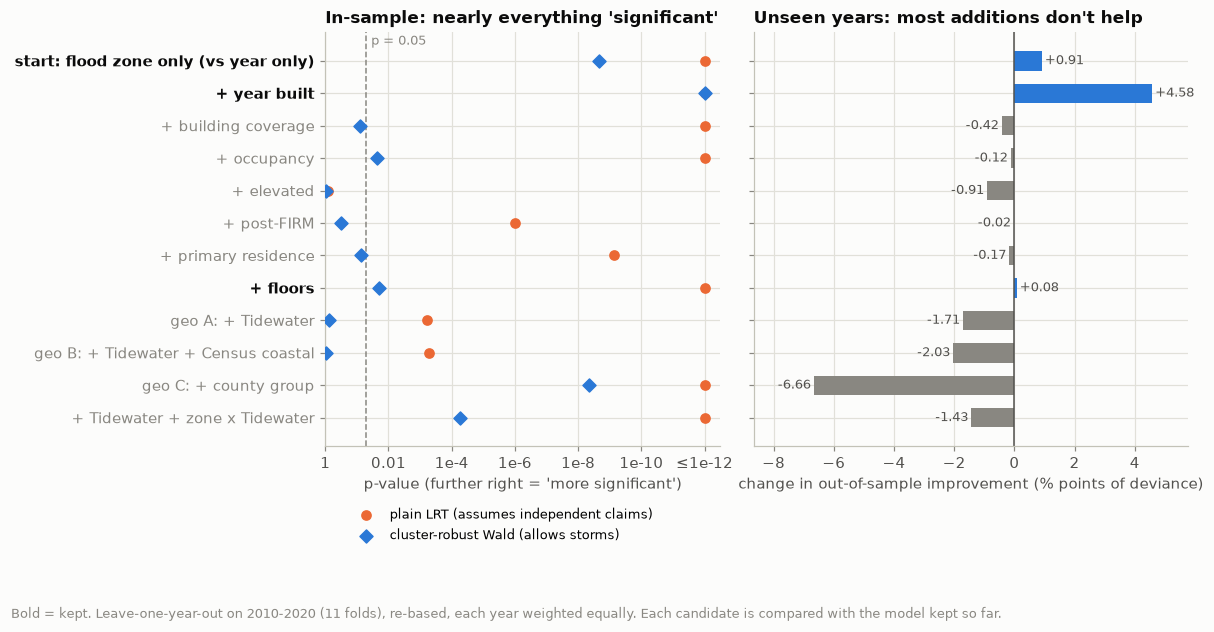

In [4]:
# Picture of the table: in-sample significance (left) vs help on unseen years (right).
s = steps.copy()
y = np.arange(len(s))[::-1]
kept = s["decision"].isin(["KEEP", "start"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True, gridspec_kw={"width_ratios": [1, 1.1]})
CAP = 12
for col, colour, label, mk in [("LRT_p", ORANGE, "plain LRT (assumes independent claims)", "o"),
                               ("cluster_Wald_p", BLUE, "cluster-robust Wald (allows storms)", "D")]:
    v = np.minimum(-np.log10(s[col].clip(lower=1e-300)), CAP)
    a1.scatter(v, y, color=colour, marker=mk, s=36, label=label, zorder=3)
a1.axvline(-np.log10(0.05), color=MUTED, ls="--", lw=1)
a1.text(-np.log10(0.05) + 0.15, len(s) - 0.4, "p = 0.05", color=MUTED, fontsize=8.5, va="center")
a1.set_xlim(0, CAP + 0.5)
a1.set_xticks([0, 2, 4, 6, 8, 10, 12], ["1", "0.01", "1e-4", "1e-6", "1e-8", "1e-10", "≤1e-12"])
a1.set_xlabel("p-value (further right = 'more significant')")
a1.set_yticks(y, s.index)
for t, k in zip(a1.get_yticklabels(), kept):
    t.set_color(INK if k else MUTED); t.set_fontweight("bold" if k else "normal")
a1.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), fontsize=8.5, ncol=1)
a1.set_title("In-sample: nearly everything 'significant'")
d = s["d_devLOYO_pct"]
a2.barh(y, d, color=np.where(kept, BLUE, MUTED), height=0.6)
a2.axvline(0, color=INK_2, lw=1)
for yi, v in zip(y, d):
    a2.text(v + (0.1 if v >= 0 else -0.1), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=8.5, color=INK_2)
a2.set_xlim(min(d.min() - 2.0, -1), max(d.max() + 1.2, 1))
a2.set_xlabel("change in out-of-sample improvement (% points of deviance)")
a2.set_title("Unseen years: most additions don't help")
fig.text(0.01, -0.09, "Bold = kept. Leave-one-year-out on 2010-2020 (11 folds), re-based, each year weighted equally. "
         "Each candidate is compared with the model kept so far.", color=MUTED, fontsize=8.5)
fig.tight_layout()
save(fig, "model_build_steps")
plt.show()

**Reading the build.**
- **Flood zone** and **year built** carry the model. Year built improves *every* held-out year (11 of 11 folds). This matches Milestone 6, which found building age the most stable factor.
- **Floors** passes narrowly (cluster Wald p ≈ 0.02, a small out-of-sample gain in 8 of 11 folds). It is the weakest factor kept, and the first to revisit.
- **Building coverage, occupancy, post-FIRM and primary residence** all pass the plain LRT easily, but fail once storms are allowed for, or make unseen years slightly worse. Their effects are either small once zone and age are in the model (post-FIRM mostly *is* building age), or they change from storm to storm (coverage band: 0.94× in cat years vs 3.4× in normal years, Milestone 6).
- **Elevated** adds literally nothing once zone and year built are in (Δdeviance ≈ 0). See section 2c.
- **Geography fails on unseen years.** County group improves the training fit enormously (Δdeviance ≈ 1,170), but makes held-out years *worse* in 10 of 11 folds. Which counties flood depends on where the storm goes, so a county's past "luck" doesn't carry over to a new year. Tidewater and the zone × tidal interaction behave the same way: real in-sample (the interaction's cluster Wald p < 0.0001), but they don't transfer, because the coastal effect *flips* between hurricane and inland-flood years (Milestone 6). This is the clearest example of why we validate on whole held-out years.

## 2b. The final model and its relativity table

The features are now frozen. For the relativity table, the model is **refitted on all 16 years (2010–2025)**: more data gives more precise estimates, and validation is done by refitting inside each fold (section 2e).

**How to read it.** A relativity is e^β: the factor that multiplies the claim rate compared with the **base level** (relativity 1.00; the level with the most exposure, as in Milestone 6), *holding the other features fixed*. 0.46 means 54% fewer claims per policy-year. The **95% confidence interval** is the range of relativities consistent with the data. We show two:
- **storm-aware** (cluster-robust by county group × year), the one we recommend (see 2d for why);
- **plain Poisson**, which assumes every claim is independent and is far too narrow for flood.

In [5]:
final = fg.fit_glm(tab, FINAL, FINAL_INTER)
final_q = fg.fit_glm(tab, FINAL, FINAL_INTER, cov="quasi")
final_c = fg.fit_glm(tab, FINAL, FINAL_INTER, cov="cluster")
rel = fg.relativity_table(final, tab, {"poisson": final.result, "quasi": final_q.result, "cluster": final_c.result})

# Checks: predictions balance to the actual claims; relativities point the expected way.
assert np.isclose(final.predict(tab, "fitted").sum(), tab["claims"].sum(), rtol=1e-6)
assert np.isclose(final.predict(tab, "average").sum(), tab["claims"].sum(), rtol=1e-6)
r = rel.set_index(["feature", "level"])["relativity"]
assert r[(Z, "B/C/X moderate-low risk")] < 1 and r[("construction_band", "before 1960")] > 1

base_rate = np.exp(final.params["const"] + final.avg_year_log)
print("Base levels: " + "; ".join(f"{NICE[f]} = {nice_level(f, b)}" for f, b in final.spec.bases.items() if f != "year"))
print(f"Base-cell frequency (all base levels, average year): {1000 * base_rate:.2f} paid claims per 1,000 policy-years")
print(f"Cells: {len(tab):,} | parameters: {len(final.params)} ({len(final.params) - len(final.spec.levels['year'])} for features, "
      f"{len(final.spec.levels['year']) - 1} for year)\n")

table = pd.DataFrame({
    "feature": rel["feature"].map(NICE), "level": [nice_level(f, l) for f, l in zip(rel["feature"], rel["level"])],
    "exposure share": rel["exposure_share"].map("{:.1%}".format), "paid claims": rel["claims"].map("{:,}".format),
    "relativity e^β": rel["relativity"].map("{:.3f}".format),
    "95% CI storm-aware": [("BASE" if b else f"{lo:.2f} – {hi:.2f}") for b, lo, hi in zip(rel["is_base"], rel["lo_cluster"], rel["hi_cluster"])],
    "95% CI plain Poisson": [("BASE" if b else f"{lo:.2f} – {hi:.2f}") for b, lo, hi in zip(rel["is_base"], rel["lo_poisson"], rel["hi_poisson"])],
})
display(table)

Base levels: Flood zone = A/V high risk; Year built = 1980-1999; Floors = 2 floors
Base-cell frequency (all base levels, average year): 4.82 paid claims per 1,000 policy-years
Cells: 173,363 | parameters: 22 (6 for features, 15 for year)



,feature,level,exposure share,paid claims,relativity e^β,95% CI storm-aware,95% CI plain Poisson
0,Flood zone,A/V high risk,51.0%,"6,798",1.000,BASE,BASE
1,Flood zone,B/C/X moderate-low risk,49.0%,"2,664",0.458,0.34 – 0.61,0.44 – 0.48
2,Year built,1980-1999,30.8%,"1,554",1.000,BASE,BASE
3,Year built,before 1960,21.1%,"3,172",2.728,2.04 – 3.66,2.57 – 2.90
4,Year built,1960-1979,28.9%,"4,164",2.748,2.41 – 3.13,2.59 – 2.91
5,Year built,2000 or later,19.1%,572,0.643,0.51 – 0.80,0.58 – 0.71
6,Floors,2 floors,50.5%,"4,724",1.000,BASE,BASE
7,Floors,1 floor,32.6%,"2,985",0.892,0.81 – 0.99,0.85 – 0.93
8,Floors,3+ floors,16.9%,"1,753",1.132,0.92 – 1.40,1.07 – 1.20


saved reports\figures\05_relativities.png


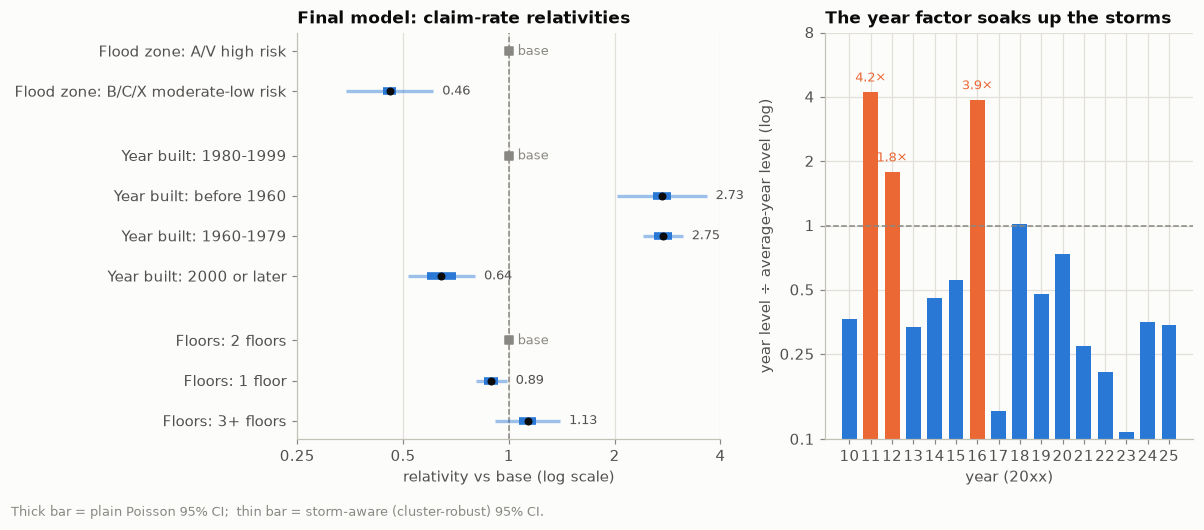

In [6]:
# Forest plot of the relativities, plus the year factor the model absorbs.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ypos, labels, yy = [], [], 0
for f in FINAL:
    sub = rel[rel["feature"] == f]
    for _, row in sub.iterrows():
        ypos.append(yy); labels.append(f"{NICE[f]}: {nice_level(f, row['level'])}"); yy -= 1
    yy -= 0.6
rr = rel[rel["feature"].isin(FINAL)].reset_index(drop=True)
ypos = np.array(ypos)
for i, row in rr.iterrows():
    if row["is_base"]:
        a1.scatter(1, ypos[i], marker="s", s=26, color=MUTED, zorder=3)
        a1.text(1.06, ypos[i], "base", va="center", fontsize=8.5, color=MUTED)
        continue
    a1.plot([row["lo_cluster"], row["hi_cluster"]], [ypos[i]] * 2, color=BLUE, lw=2.2, alpha=0.45, solid_capstyle="butt")
    a1.plot([row["lo_poisson"], row["hi_poisson"]], [ypos[i]] * 2, color=BLUE, lw=5, solid_capstyle="butt")
    a1.scatter(row["relativity"], ypos[i], color=INK, s=18, zorder=3)
    a1.text(row["hi_cluster"] * 1.06, ypos[i], f"{row['relativity']:.2f}", va="center", fontsize=8.5, color=INK_2)
log_rel_axis(a1, 0.25, 4)
a1.set_yticks(ypos, labels)
a1.grid(axis="y", visible=False)
a1.set_xlabel("relativity vs base (log scale)")
a1.set_title("Final model: claim-rate relativities")
fig.text(0.01, -0.03, "Thick bar = plain Poisson 95% CI;  thin bar = storm-aware (cluster-robust) 95% CI.", fontsize=8.5, color=MUTED)

yrs = final.spec.levels["year"]
idx = np.array([np.exp(final.params.get(f"year[{y}]", 0.0) + final.params["const"]) for y in yrs]) / base_rate
order = np.argsort([int(y) for y in yrs])
yrs_o, idx_o = [yrs[i] for i in order], idx[order]
cols = [ORANGE if int(y) in val.CAT_YEARS else BLUE for y in yrs_o]
a2.bar(range(len(yrs_o)), idx_o, color=cols, width=0.7)
log_rel_axis(a2, 0.1, 8, axis="y")
a2.set_xticks(range(len(yrs_o)), [y[2:] for y in yrs_o])
a2.set_xlabel("year (20xx)")
a2.set_ylabel("year level ÷ average-year level (log)")
a2.set_title("The year factor soaks up the storms")
for i, (y, v) in enumerate(zip(yrs_o, idx_o)):
    if int(y) in val.CAT_YEARS:
        a2.text(i, v * 1.12, f"{v:.1f}×", ha="center", fontsize=8.5, color=ORANGE)
fig.tight_layout()
save(fig, "relativities")
plt.show()

## 2c. One-way vs GLM relativities: what confounding did

The **one-way** relativity (Milestone 6) compares levels of one feature, ignoring everything else. The **GLM** relativity compares them *holding the other features fixed*. When a feature travels with another risky feature, the two disagree. That's **confounding**.

To see every shortlist feature adjusted, the table also shows a **"full" GLM** containing all nine shortlist features (zone, year built, coverage, occupancy, elevated, post-FIRM, primary residence, floors, Tidewater). It is not our final model (2a showed most of those features don't help on unseen years), but it shows what each one-way number turns into once the others are held fixed. All three columns use the same data (all 16 years, exposure > 0).

In [7]:
FULL = ["flood_zone_group", "construction_band", "building_coverage_band", "occupancy_group", "elevated",
        "post_firm", "primary_residence", "floors_group", "coastal_tidal"]
full = fg.fit_glm(tab, FULL)
full_rel = fg.relativity_table(full, tab).set_index(["feature", "level"])["relativity"]
final_rel = rel.set_index(["feature", "level"])["relativity"]

rows = []
for f in FULL:
    t = ow.one_way(df, f)
    assert str(t.attrs["base"]) == full.spec.bases[f], f      # same base level in both views
    for lvl in full.spec.levels[f]:
        one = t.loc[[i for i in t.index if str(i) == lvl][0], "frequency_rel"]
        rows.append({"feature": f, "level": lvl, "base": lvl == full.spec.bases[f], "one_way": one,
                     "full_glm": full_rel[(f, lvl)], "final_glm": final_rel.get((f, lvl), np.nan)})
cmp = pd.DataFrame(rows)
cmp["glm_over_oneway"] = cmp["full_glm"] / cmp["one_way"]
cmp.to_csv(ROOT / "reports" / "04_oneway_vs_glm.csv", index=False)
view = cmp[~cmp["base"]].copy()
display(pd.DataFrame({
    "feature": view["feature"].map(NICE), "level": [nice_level(f, l) for f, l in zip(view["feature"], view["level"])],
    "one-way": view["one_way"].map("{:.2f}".format), "full GLM": view["full_glm"].map("{:.2f}".format),
    "final GLM": view["final_glm"].map(lambda v: "not in model" if pd.isna(v) else f"{v:.2f}"),
    "GLM ÷ one-way": view["glm_over_oneway"].map("{:.2f}".format),
}).reset_index(drop=True))

,feature,level,one-way,full GLM,final GLM,GLM ÷ one-way
0,Flood zone,B/C/X moderate-low risk,0.41,0.46,0.46,1.12
1,Year built,before 1960,2.98,2.21,2.73,0.74
2,Year built,1960-1979,2.85,2.29,2.75,0.80
3,Year built,2000 or later,0.59,0.67,0.64,1.14
4,Building coverage,$0 (contents only),2.03,1.78,not in model,0.88
5,Building coverage,under $100K,1.89,1.14,not in model,0.60
6,Building coverage,$100K-$249K,1.79,1.10,not in model,0.61
7,Occupancy,multi-unit residential,1.43,1.39,not in model,0.97
8,Occupancy,non-residential,1.11,0.94,not in model,0.84
9,Elevated,yes,1.08,0.99,not in model,0.92


saved reports\figures\05_oneway_vs_glm.png


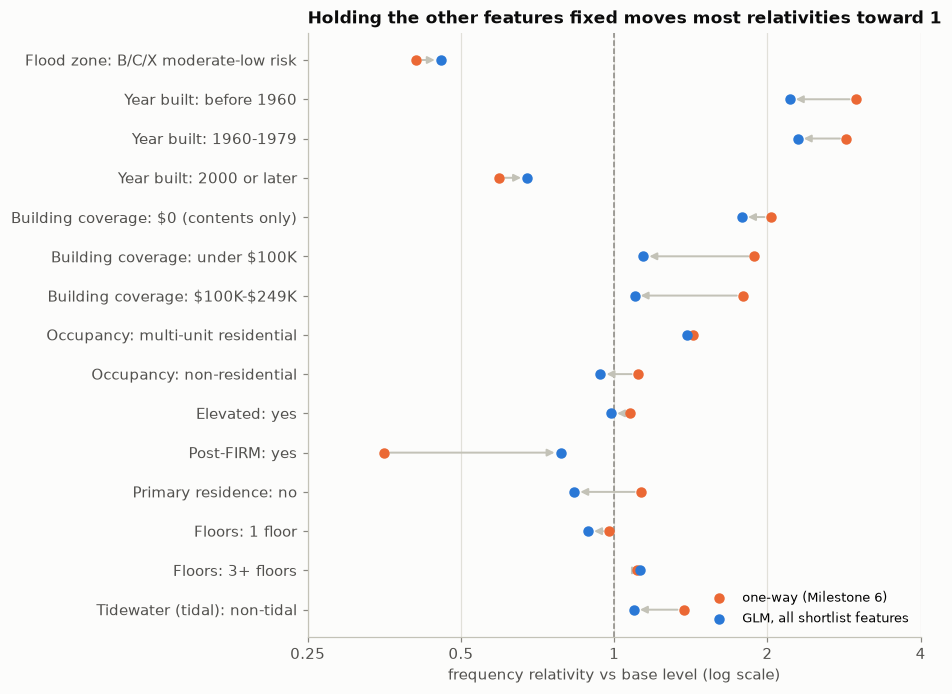

In [8]:
v = view.reset_index(drop=True)
y = np.arange(len(v))[::-1]
fig, ax = plt.subplots(figsize=(8.6, 6.4))
for yi, (_, row) in zip(y, v.iterrows()):
    ax.annotate("", xy=(row["full_glm"], yi), xytext=(row["one_way"], yi),
                arrowprops=dict(arrowstyle="-|>", color=AXIS, lw=1.3, shrinkA=4, shrinkB=4))
ax.scatter(v["one_way"], y, color=ORANGE, s=34, zorder=3, label="one-way (Milestone 6)")
ax.scatter(v["full_glm"], y, color=BLUE, s=34, zorder=3, label="GLM, all shortlist features")
log_rel_axis(ax, 0.25, 4)
ax.set_yticks(y, [f"{NICE[f]}: {nice_level(f, l)}" for f, l in zip(v["feature"], v["level"])])
ax.grid(axis="y", visible=False)
ax.set_xlabel("frequency relativity vs base level (log scale)")
ax.set_title("Holding the other features fixed moves most relativities toward 1")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
save(fig, "oneway_vs_glm")
plt.show()

**Where they differ, and why** (numbers from the table above; the one-way values differ slightly from Milestone 6's because the 95 unmatched claims are excluded here):
- **Post-FIRM: 0.35 one-way → about 0.79.** "Built after the first flood map" is mostly another way of saying "newer building" (Cramér's V with year built = 0.81). Once year built is in the model, little is left for post-FIRM to explain, which is why it was dropped in 2a.
- **Year built shrinks a little** (pre-1960 about 3.0 → 2.2 in the full GLM, 2.7 in the final model). In the full model, post-FIRM takes part of the age effect. Without post-FIRM, year built carries all of it.
- **Elevated: 1.08 → about 0.99.** One-way, elevated buildings look *riskier* because 67% of them are in A/V zones, where floodplain rules require elevation. Holding zone (and age) fixed, the apparent extra risk disappears. This is Simpson's paradox: the one-way and adjusted answers point in different directions.
- **Primary residence (not primary): 1.13 → about 0.83.** Second homes are concentrated in high-risk beach zones. After zone, they are, if anything, *less* likely to claim. (Their claims are bigger, which is a severity effect for Milestone 8.)
- **Building coverage under $100K: 1.89 → about 1.14.** Low limits are common inland and on older homes. Most of the one-way effect was geography and building age.
- **Tidewater (non-tidal): 1.37 → about 1.09**, since flood zone and building mix explain most of the inland/coastal difference.
- **Flood zone barely moves** (0.41 → about 0.46). It's the strongest factor and not much confounded.

## 2d. Over-dispersion: is Poisson's "variance = mean" true here?

A Poisson model assumes the **variance** of the claim count equals its **mean**. If storms make claims arrive in clumps, the real variance is bigger (**over-dispersion**). The coefficients from a Poisson fit are still fine (unbiased), but its **standard errors and confidence intervals are too narrow**, and its tests too eager.

Tests on the final model (all years):
- **Pearson φ** = Σ (actual − expected)² / expected, divided by the degrees of freedom. About 1 if Poisson is right.
- **Cameron–Trivedi test**: a formal test of whether the variance grows faster than the mean.

Then three fixes, compared:
1. **Quasi-Poisson.** Same coefficients; every standard error × √φ.
2. **Negative binomial (NB2).** A different distribution with variance = μ + α·μ². α is estimated by maximum likelihood. The coefficients change a little, because big cells get relatively less weight.
3. **Cluster-robust ("sandwich") errors.** Same coefficients as Poisson; the standard errors are computed from how much whole **clusters** (county group × year) actually bounce around, so claims from the same storm in the same area aren't treated as independent. A **year-cluster** version (all of Virginia in a year as one cluster) is a stricter sensitivity check, with only 16 clusters.

In [9]:
od = fg.overdispersion_tests(final, tab)
print(f"Pearson phi = {od['pearson_phi']:.2f}   deviance/df = {od['deviance_over_df']:.2f}")
print(f"Cameron-Trivedi: alpha = {od['CT_alpha']:.2f}, t = {od['CT_t']:.1f}, one-sided p = {fmt_p(od['CT_p_one_sided'])}"
      "  ->  over-dispersion is present")

# The SAME model fitted on coarser tables: identical coefficients, but phi grows as cells are
# combined. Extra variance that grows when you add cells together = cells moving TOGETHER (storms).
print("\nSame model, same coefficients, different table sizes:")
for name, keys in [("rating cells (features + county group + all other features)", fg.CANDIDATES),
                   ("features + county group + year", FINAL + ["county_group"]),
                   ("features + Tidewater flag + year", FINAL + ["coastal_tidal"]),
                   ("features + year only (statewide)", FINAL)]:
    a = fg.aggregate(df, keys)
    m = fg.fit_glm(a, FINAL, FINAL_INTER)
    assert np.allclose(m.params, final.params, atol=1e-6)
    print(f"  {name:64s} {len(a):>8,} rows   phi = {m.result.pearson_chi2 / m.result.df_resid:7.2f}")

Pearson phi = 1.96   deviance/df = 0.22
Cameron-Trivedi: alpha = 3.79, t = 23.8, one-sided p = <0.0001  ->  over-dispersion is present

Same model, same coefficients, different table sizes:


  rating cells (features + county group + all other features)       173,363 rows   phi =    1.96
  features + county group + year                                     13,207 rows   phi =    3.53
  features + Tidewater flag + year                                      768 rows   phi =   12.14
  features + year only (statewide)                                      384 rows   phi =    6.85


In [10]:
final_cy = fg.fit_glm(tab, FINAL, FINAL_INTER, cov="cluster", cluster_by=("year",))
nb = fg.fit_negbin(tab, FINAL, FINAL_INTER)
print(f"Negative binomial alpha = {nb.alpha:.2f}  (variance = mu + {nb.alpha:.2f} mu^2)")
print(f"AIC: Poisson {final.result.aic:,.0f}   negative binomial {nb.result.aic:,.0f}  (lower is better)")

methods = {"plain Poisson": final.result, "quasi-Poisson": final_q.result,
           "cluster: county group × year": final_c.result, "cluster: year (strict)": final_cy.result}
ci = fg.relativity_table(final, tab, methods)
ci_nb = fg.relativity_table(nb, tab, {"nb": nb.result})
ci["nb_relativity"], ci["lo_negative binomial"], ci["hi_negative binomial"] = ci_nb["relativity"], ci_nb["lo_nb"], ci_nb["hi_nb"]
ci = ci[~ci["is_base"]].reset_index(drop=True)
METHODS = ["plain Poisson", "quasi-Poisson", "negative binomial", "cluster: county group × year", "cluster: year (strict)"]
out = pd.DataFrame({"level": [f"{NICE[f]}: {nice_level(f, l)}" for f, l in zip(ci["feature"], ci["level"])],
                    "Poisson / quasi / cluster relativity": ci["relativity"].map("{:.3f}".format),
                    "NB relativity": ci["nb_relativity"].map("{:.3f}".format)})
for m in METHODS:
    out[f"CI {m}"] = [f"{lo:.2f}–{hi:.2f}" for lo, hi in zip(ci[f"lo_{m}"], ci[f"hi_{m}"])]
display(out)
width = pd.DataFrame({m: np.log(ci[f"hi_{m}"] / ci[f"lo_{m}"]) for m in METHODS})
print("Average CI width relative to plain Poisson (on the log scale):")
print((width.div(width["plain Poisson"], axis=0)).mean().round(2).to_string())

Negative binomial alpha = 3.63  (variance = mu + 3.63 mu^2)
AIC: Poisson 49,301   negative binomial 41,863  (lower is better)


,level,Poisson / quasi / cluster relativity,NB relativity,CI plain Poisson,CI quasi-Poisson,CI negative binomial,CI cluster: county group × year,CI cluster: year (strict)
0,Flood zone: B/C/X moderate-low risk,0.458,0.610,0.44–0.48,0.43–0.49,0.57–0.65,0.34–0.61,0.29–0.72
1,Year built: before 1960,2.728,2.696,2.57–2.90,2.51–2.97,2.47–2.94,2.04–3.66,2.12–3.51
2,Year built: 1960-1979,2.748,2.558,2.59–2.91,2.53–2.98,2.35–2.79,2.41–3.13,2.38–3.17
3,Year built: 2000 or later,0.643,0.680,0.58–0.71,0.56–0.73,0.60–0.77,0.51–0.80,0.52–0.79
4,Floors: 1 floor,0.892,0.923,0.85–0.93,0.84–0.95,0.86–0.99,0.81–0.99,0.77–1.03
5,Floors: 3+ floors,1.132,1.084,1.07–1.20,1.05–1.22,1.00–1.18,0.92–1.40,0.86–1.49


Average CI width relative to plain Poisson (on the log scale):
plain Poisson                   1.00
quasi-Poisson                   1.40
negative binomial               1.44
cluster: county group × year    3.62
cluster: year (strict)          4.49


In [11]:
# Which distribution predicts unseen years better? Dev-LOYO on 2010-2020 (NB alpha re-estimated in every fold).
sc_p, _ = fg.loyo_scores(dev, lambda tr: fg.fit_glm(tr, FINAL, FINAL_INTER), val.DEV_YEARS)
sc_nb, _ = fg.loyo_scores(dev, lambda tr: fg.fit_negbin(tr, FINAL, FINAL_INTER), val.DEV_YEARS)
dist = pd.DataFrame({"Poisson / quasi-Poisson": sc_p.set_index("test_year")["improvement_rebased_pct"],
                     "negative binomial": sc_nb.set_index("test_year")["improvement_rebased_pct"]})
print("Dev-LOYO: % Poisson-deviance improvement over the no-features model (re-based), per held-out year")
display(dist.T.round(2))
print(f"Mean over 11 folds: Poisson {dist.iloc[:, 0].mean():.2f}%   NB {dist.iloc[:, 1].mean():.2f}%   "
      f"(NB better in {(dist.iloc[:, 1] > dist.iloc[:, 0]).sum()} of 11 folds)")
print(f"Raw A/E summed over folds: Poisson {sc_p['test_claims'].sum() / sc_p['pred_claims'].sum():.3f}   "
      f"NB {sc_nb['test_claims'].sum() / sc_nb['pred_claims'].sum():.3f}")

Dev-LOYO: % Poisson-deviance improvement over the no-features model (re-based), per held-out year


test_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
Poisson / quasi-Poisson,0.31,17.79,16.46,4.80,0.97,10.54,7.98,-2.17,1.46,0.65,2.46
negative binomial,2.43,16.25,13.89,5.07,2.31,9.73,10.08,-0.79,2.35,2.50,3.88


Mean over 11 folds: Poisson 5.57%   NB 6.16%   (NB better in 8 of 11 folds)
Raw A/E summed over folds: Poisson 1.001   NB 1.001


saved reports\figures\05_ci_comparison.png


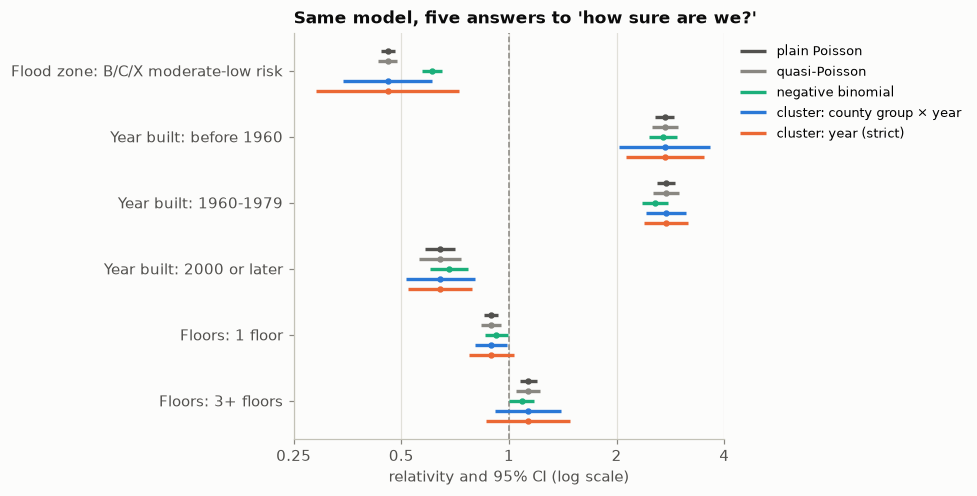

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.6))
cols = {"plain Poisson": INK_2, "quasi-Poisson": MUTED, "negative binomial": AQUA,
        "cluster: county group × year": BLUE, "cluster: year (strict)": ORANGE}
n = len(ci)
for j, m in enumerate(METHODS):
    off = (2 - j) * 0.15     # first method on top, matching the legend order
    rel_m = ci["nb_relativity"] if m == "negative binomial" else ci["relativity"]
    for i in range(n):
        yv = n - 1 - i + off
        ax.plot([ci.loc[i, f"lo_{m}"], ci.loc[i, f"hi_{m}"]], [yv, yv], color=cols[m], lw=2.2,
                label=m if i == 0 else None, solid_capstyle="butt")
        ax.scatter(rel_m[i], yv, color=cols[m], s=10, zorder=3)
log_rel_axis(ax, 0.25, 4)
ax.set_yticks(range(n)[::-1], [f"{NICE[f]}: {nice_level(f, l)}" for f, l in zip(ci["feature"], ci["level"])])
ax.grid(axis="y", visible=False)
ax.set_xlabel("relativity and 95% CI (log scale)")
ax.set_title("Same model, five answers to 'how sure are we?'")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5)
fig.tight_layout()
save(fig, "ci_comparison")
plt.show()

**Which would I use, and why?**
- Over-dispersion is **clearly present** (Cameron–Trivedi p < 0.0001). Note what happens to **φ when cells are combined**: about 2 for rating cells, 3.5 by county group, 12 by tidal/non-tidal area, all with identical coefficients. Extra variance that grows when you add cells together means the cells **move together**. That's storms, not cell-by-cell noise.
- **Negative binomial** has a much better AIC, and on unseen development years it is also *slightly* better (mean 6.2% vs 5.6% improvement, better in 8 of 11 folds). It gives big cells less weight, which damps the storm-hit A/V cells, so its zone relativity is weaker (0.61 vs 0.46). But its intervals are about as narrow as quasi-Poisson's, because it still treats cells as independent. Its answer depends on how the cells are cut (NB is not invariant to aggregation; Poisson is). And its fitted claims no longer equal the actual claims within each feature level.
- **Quasi-Poisson** fixes the problem only partly: φ measured on small cells understates the clumping.
- **Choice, for now: Poisson/quasi-Poisson point estimates with cluster-robust (county group × year) confidence intervals.**
  - The relativities are Poisson's, for three reasons. They **balance**: fitted claims equal actual claims in every level of every feature, so the rating plan reproduces the experience it was built on. They don't depend on how cells are grouped. And they are standard actuarial practice. NB's out-of-sample gain (0.6 points) is small next to what the features themselves add (5.6 points). NB stays as the main challenger, to be re-tested on all 16 years in the model-comparison milestone.
  - The intervals are storm-aware: about 3.6× wider than plain Poisson on the log scale, an honest statement of how uncertain three hurricanes make us. The **year-cluster** version is wider again (4.5×). Treat it as the pessimistic bound: all of Virginia in one storm year is one data point, and we have only 16.
- **What changes in the conclusions:** zone and year built stay clearly significant under every method. **Floors** becomes doubtful: under storm-aware intervals, 3+ floors crosses 1 (0.92–1.40) and 1 floor only just excludes it (0.81–0.99). It was kept by the development rule, but it's the weakest link.

## 2e. How well does it predict years it has never seen?

Following `docs/validation_plan.md`:
- **Headline: leave-one-year-out (LOYO) on all 16 years.** For each year, fit on the other 15 and predict the held-out year at the **average-year level** (nobody knows in advance whether a hurricane will come).
- **Baseline ("no features"):** every policy-year gets the training years' average frequency. Any useful model must beat it.
- **Raw vs re-based.** *Raw* predictions show calibration: does the total come out right? *Re-based* predictions are scaled to the year's actual total, so the score only measures whether the claims landed in the right cells (the part a model can control).
- **Metrics:** Poisson **deviance** (lower is better; reported as % improvement over the baseline), **actual ÷ expected** (A/E) claims, the **Gini** index and a **decile lift chart** (does the model rank risky cells above safe ones?).
- **Models compared:** the final GLM, the "full" nine-feature GLM from 2c (to show what the dropped features would have done), and the baseline.
- **One-time final check:** train 2010–2020 → test 2021–2025, at the end.

In [13]:
KEEP = ["flood_zone_group", "construction_band", "floors_group", "coastal_tidal", "county_group"]
sc_final, oof_final = fg.loyo_scores(tab, lambda tr: fg.fit_glm(tr, FINAL, FINAL_INTER), keep_cols=KEEP)
sc_full, oof_full = fg.loyo_scores(tab, lambda tr: fg.fit_glm(tr, FULL), keep_cols=KEEP)

per_year = pd.DataFrame({
    "cat year": sc_final["cat_year"].map({True: "CAT", False: ""}).values,
    "claims": sc_final["test_claims"].values,
    "baseline predicted": sc_final["null_claims"].round(0).astype(int).values,
    "model predicted": sc_final["pred_claims"].round(0).astype(int).values,
    "raw A/E": sc_final["actual_over_expected"].round(2).values,
    "final GLM: deviance improvement % (re-based)": sc_final["improvement_rebased_pct"].round(1).values,
    "full GLM: deviance improvement % (re-based)": sc_full["improvement_rebased_pct"].round(1).values,
    "final GLM Gini": sc_final["gini"].round(3).values,
    "full GLM Gini": sc_full["gini"].round(3).values,
}, index=sc_final["test_year"].values)
display(per_year)

long = pd.concat([sc_final.assign(model="final GLM"), sc_full.assign(model="full GLM")])
print("Re-based deviance improvement over the baseline, % (each year counts once):")
display(val.summarize_scores(long, "improvement_rebased_pct").round(2))
print("Gini:")
display(val.summarize_scores(long, "gini").round(3))
wins = (sc_final["deviance_rebased"].values < sc_full["deviance_rebased"].values).sum()
beats_null = (sc_final["improvement_rebased_pct"] > 0).sum()
print(f"Final GLM beats the baseline in {beats_null} of 16 years; beats the full GLM in {wins} of 16 years.")
print(f"Raw A/E summed over all 16 folds: {sc_final['test_claims'].sum() / sc_final['pred_claims'].sum():.3f}")
print(f"Pooled over all folds (claims-weighted): final GLM deviance "
      f"{100 * (1 - sc_final['deviance_rebased'].sum() / sc_final['null_deviance_rebased'].sum()):.1f}% better than baseline")

,cat year,claims,baseline predicted,model predicted,raw A/E,final GLM: deviance improvement % (re-based),full GLM: deviance improvement % (re-based),final GLM Gini,full GLM Gini
2010,,238,648,683,0.35,0.7,1.1,0.229,0.244
2011,CAT,2780,478,496,5.60,17.7,6.9,0.418,0.295
2012,CAT,1193,610,631,1.89,16.3,14.8,0.464,0.441
2013,,225,691,708,0.32,4.8,4.9,0.365,0.357
2014,,301,666,679,0.44,1.1,3.1,0.252,0.295
2015,,351,637,650,0.54,10.5,10.9,0.426,0.442
2016,CAT,2333,474,487,4.79,8.4,0.1,0.307,0.225
2017,,80,621,627,0.13,-1.9,-1.9,0.158,0.152
2018,,600,602,589,1.02,1.7,0.2,0.247,0.216
2019,,279,632,604,0.46,0.9,0.3,0.270,0.239


Re-based deviance improvement over the baseline, % (each year counts once):


,all folds (mean),non-cat folds (mean),cat folds (mean),all folds (median)
model,,,,
final GLM,4.72,2.54,14.14,3.00
full GLM,3.69,2.87,7.26,3.31


Gini:


,all folds (mean),non-cat folds (mean),cat folds (mean),all folds (median)
model,,,,
final GLM,0.299,0.276,0.396,0.283
full GLM,0.294,0.288,0.320,0.295


Final GLM beats the baseline in 14 of 16 years; beats the full GLM in 6 of 16 years.
Raw A/E summed over all 16 folds: 1.004
Pooled over all folds (claims-weighted): final GLM deviance 8.4% better than baseline


saved reports\figures\05_loyo_by_year.png


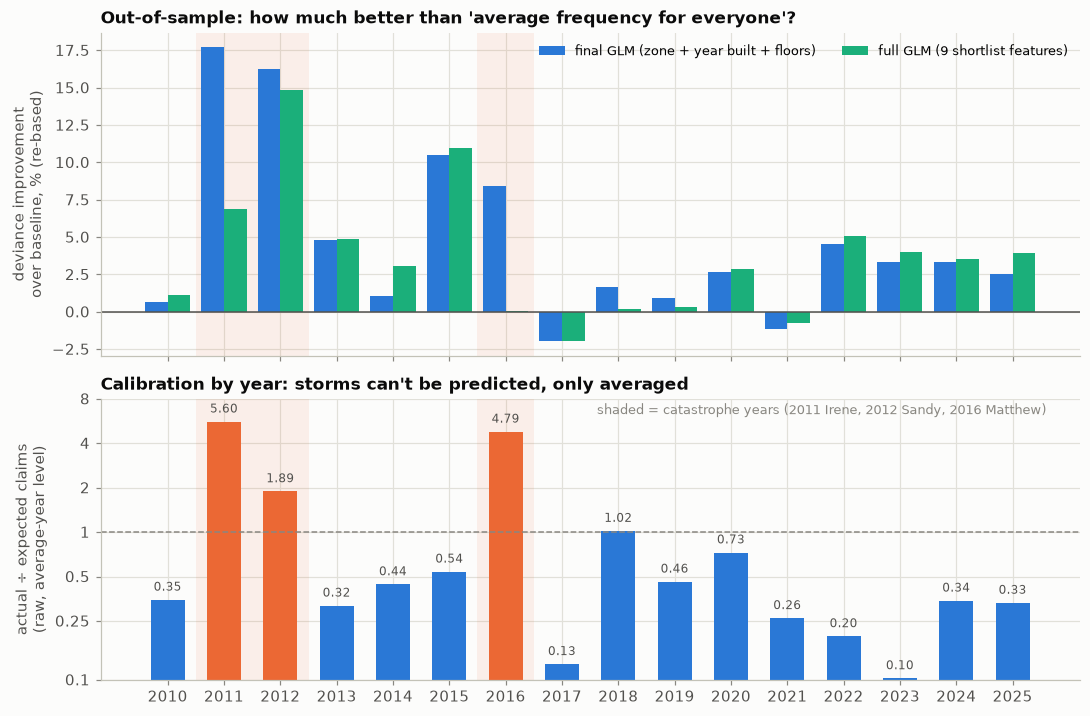

In [14]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]})
yrs = sc_final["test_year"].values
x = np.arange(len(yrs))
for a in (a1, a2):
    for i, yv in enumerate(yrs):
        if val.is_cat_year(yv):
            a.axvspan(i - 0.5, i + 0.5, color=ORANGE, alpha=0.09, lw=0)
a1.bar(x - 0.2, sc_final["improvement_rebased_pct"], 0.4, color=BLUE, label="final GLM (zone + year built + floors)")
a1.bar(x + 0.2, sc_full["improvement_rebased_pct"], 0.4, color=AQUA, label="full GLM (9 shortlist features)")
a1.axhline(0, color=INK_2, lw=1)
a1.set_ylabel("deviance improvement\nover baseline, % (re-based)")
a1.set_title("Out-of-sample: how much better than 'average frequency for everyone'?")
a1.legend(loc="upper right", fontsize=8.5, ncol=2)
ae = sc_final["actual_over_expected"].values
a2.bar(x, ae, 0.6, color=[ORANGE if val.is_cat_year(yv) else BLUE for yv in yrs])
log_rel_axis(a2, 0.1, 8, axis="y")
a2.set_ylabel("actual ÷ expected claims\n(raw, average-year level)")
a2.set_title("Calibration by year: storms can't be predicted, only averaged")
for i, v in enumerate(ae):
    a2.text(i, v * 1.1, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color=INK_2)
a2.set_xticks(x, yrs)
a2.text(len(x) - 0.4, 6.3, "shaded = catastrophe years (2011 Irene, 2012 Sandy, 2016 Matthew)", ha="right", fontsize=8.5, color=MUTED)
fig.tight_layout()
save(fig, "loyo_by_year")
plt.show()

saved reports\figures\05_ae_by_feature.png


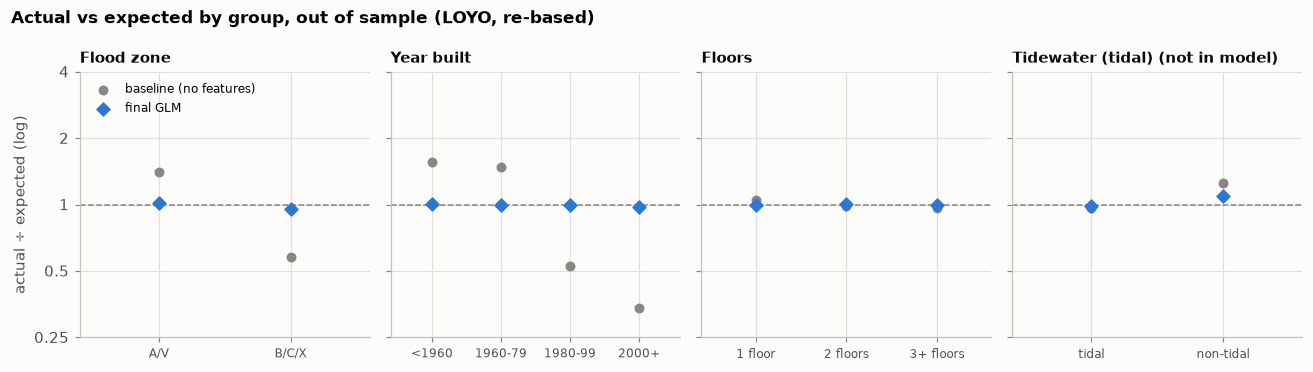

,exposure,claims,A/E final GLM
county_group,,,
51810,298421,2070,1.28
51650,158300,834,0.64
51710,154653,1332,1.14
51550,131134,619,0.97
51059,75514,517,1.28
51740,55140,423,1.01
51001,54155,327,0.82
51735,50916,410,1.07
51199,50638,75,0.27


County groups with A/E above 1.5 or below 0.67: 16 of 35


In [15]:
# Actual / expected by feature, pooled over the 16 LOYO folds, re-based within each year.
# A/E near 1 = the model puts the right number of claims in that group.
def ae_by(oof, col, pred):
    t = oof.groupby(oof[col].astype(str), observed=True)[["exposure", "claims", pred]].sum()
    return t["claims"] / t[pred], t["exposure"]      # string index (bool levels would act as a mask)

SHORT = {"A/V high risk": "A/V", "B/C/X moderate-low risk": "B/C/X", "before 1960": "<1960", "1960-1979": "1960-79",
         "1980-1999": "1980-99", "2000 or later": "2000+"}
g = oof_final.groupby("year")
oo = oof_final.assign(null_rb=oof_final["pred_null"] * g["claims"].transform("sum") / g["pred_null"].transform("sum"))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, col in zip(axes, ["flood_zone_group", "construction_band", "floors_group", "coastal_tidal"]):
    ae_m, e = ae_by(oof_final, col, "pred_rebased")
    ae_n, _ = ae_by(oo, col, "null_rb")
    idx = [l for l in fg.LEVEL_ORDER.get(col, list(e.sort_values(ascending=False).index)) if l in ae_m.index]
    xs = np.arange(len(idx))
    ax.scatter(xs, ae_n[idx], color=MUTED, s=30, label="baseline (no features)", zorder=3)
    ax.scatter(xs, ae_m[idx], color=BLUE, s=36, marker="D", label="final GLM", zorder=3)
    log_rel_axis(ax, 0.25, 4, axis="y")
    ax.set_xticks(xs, [SHORT.get(i, nice_level(col, i)) for i in idx],
                  rotation=0, fontsize=8)
    ax.set_xlim(-0.6, len(xs) - 0.4)
    ax.set_title(NICE[col] + ("" if col in FINAL else " (not in model)"), fontsize=10)
axes[0].set_ylabel("actual ÷ expected (log)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Actual vs expected by group, out of sample (LOYO, re-based)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save(fig, "ae_by_feature")
plt.show()

# County group as a table (too many levels for a chart): the biggest 12 by exposure + the pools.
ae_c, e_c = ae_by(oof_final, "county_group", "pred_rebased")
cl = oof_final.groupby(oof_final["county_group"].astype(str))["claims"].sum()
ctab = pd.DataFrame({"exposure": e_c.round(0).astype(int), "claims": cl, "A/E final GLM": ae_c.round(2)})
pools = [i for i in ctab.index if str(i).startswith("Other")]
display(pd.concat([ctab.drop(pools).sort_values("exposure", ascending=False).head(12), ctab.loc[pools]]))
print(f"County groups with A/E above 1.5 or below 0.67: {int(((ae_c > 1.5) | (ae_c < 1 / 1.5)).sum())} of {len(ae_c)}")

**Reading the A/E charts.** The grey dots show how wrong the no-features baseline is for each group. For example, it puts far too many claims in moderate-low zones and in buildings from 1980 on. The blue diamonds show the GLM pulling the features it uses back to about 1. **Tidewater is not in the model**, and it shows a leftover gap between tidal and non-tidal areas. County-level A/E varies a lot too. That is the geography signal the model could not use reliably: it's real on average, but its direction depends on the storm (section 2a). It's the main thing to improve later, e.g. with credibility-weighted county factors or XGBoost (planned for the week-5 XGBoost milestone).

saved reports\figures\05_lift_chart.png


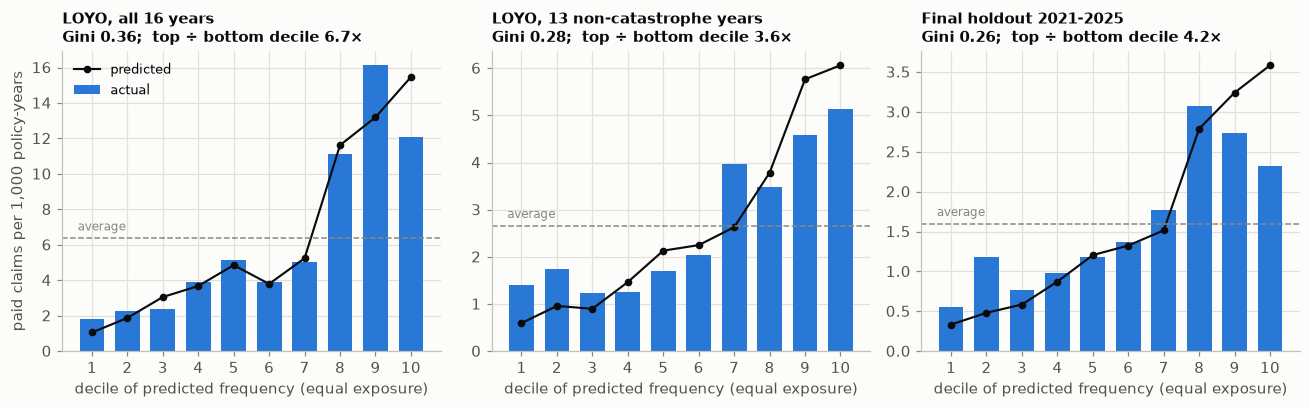

,exposure,claims,actual_freq_per_1000,pred_freq_per_1000,actual_relative_to_average
bucket,,,,,
1,148237.87,266.0,1.79,1.05,0.28
2,148242.52,334.0,2.25,1.88,0.35
3,148227.93,355.0,2.39,3.05,0.38
4,148248.43,582.0,3.93,3.68,0.62
5,148082.49,762.0,5.15,4.85,0.81
6,148399.85,580.0,3.91,3.79,0.61
7,148244.95,749.0,5.05,5.24,0.79
8,148238.62,1651.0,11.14,11.62,1.74
9,148192.49,2390.0,16.13,13.20,2.53


In [16]:
# Decile lift charts: LOYO all folds, LOYO non-cat folds, and the one-time 2021-2025 holdout.
train_h, test_h = val.time_holdout(tab)
m_h = fg.fit_glm(train_h, FINAL, FINAL_INTER)
full_h = fg.fit_glm(train_h, FULL)
ho = test_h[["year", "exposure", "claims"]].copy()
ho["pred"], ho["pred_full"] = m_h.predict(test_h), full_h.predict(test_h)
ho["pred_null"] = fg.null_prediction(train_h, test_h)
ho["relative_rate"] = m_h.relative_rate(test_h)
for c in ["pred", "pred_full", "pred_null"]:     # re-base within each test year
    ho[c + "_rb"] = ho[c] * ho.groupby("year")["claims"].transform("sum") / ho.groupby("year")[c].transform("sum")

panels = [("LOYO, all 16 years", oof_final), ("LOYO, 13 non-catastrophe years", oof_final[~oof_final["year"].isin(val.CAT_YEARS)]),
          ("Final holdout 2021-2025", ho.rename(columns={"pred_rb": "pred_rebased"}))]
# Note: ranking by the RE-BASED prediction would sort storm-year cells to the top and flatter the chart.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=False)
lifts = {}
for ax, (title, d) in zip(axes, panels):
    # Rank cells by the product of their feature relativities (from the model that predicted
    # them). Ranking on raw or re-based predictions across years would partly rank YEARS
    # (each fold has its own average-year level; storm years are re-based far higher).
    rank = d["relative_rate"]
    lt = fg.lift_table(d["claims"], d["pred_rebased"], d["exposure"], rank_by=rank)
    lifts[title] = lt
    ax.bar(lt.index, lt["actual_freq_per_1000"], color=BLUE, width=0.7, label="actual")
    ax.plot(lt.index, lt["pred_freq_per_1000"], color=INK, marker="o", ms=4, lw=1.4, label="predicted")
    avg = 1000 * d["claims"].sum() / d["exposure"].sum()
    ax.axhline(avg, color=MUTED, ls="--", lw=1)
    ax.text(0.6, avg * 1.04, "average", color=MUTED, fontsize=8, va="bottom")
    g = fg.gini(d["claims"], rank * d["exposure"], d["exposure"])
    ax.set_title(f"{title}\nGini {g:.2f};  top ÷ bottom decile {lt['actual_freq_per_1000'].iloc[-1] / max(lt['actual_freq_per_1000'].iloc[0], 1e-9):.1f}×", fontsize=10)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("decile of predicted frequency (equal exposure)")
axes[0].set_ylabel("paid claims per 1,000 policy-years")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
save(fig, "lift_chart")
plt.show()
display(lifts["LOYO, all 16 years"][["exposure", "claims", "actual_freq_per_1000", "pred_freq_per_1000", "actual_relative_to_average"]].round(2))

In [17]:
# The one-time final holdout: train 2010-2020, test 2021-2025 (scored once, after all choices were frozen).
rows = []
for yv in val.HOLDOUT_YEARS:
    t = ho[ho["year"] == yv]
    for name, col in [("final GLM", "pred"), ("full GLM", "pred_full")]:
        rows.append({"model": name, "year": yv, **fg.score_fold(t, t[col].to_numpy(), t["pred_null"].to_numpy())})
hs = pd.DataFrame(rows)
display(hs.pivot(index="year", columns="model", values="improvement_rebased_pct").round(1)
          .assign(claims=hs.groupby("year")["test_claims"].first(),
                  raw_AE_final=hs[hs["model"] == "final GLM"].set_index("year")["actual_over_expected"].round(2)))
for name, col in [("final GLM", "pred"), ("full GLM", "pred_full")]:
    d_m, d_n = fg.poisson_deviance(ho["claims"], ho[col + "_rb"]), fg.poisson_deviance(ho["claims"], ho["pred_null_rb"])
    print(f"{name}: 2021-2025 pooled re-based deviance improvement {100 * (1 - d_m / d_n):.1f}%, "
          f"Gini {fg.gini(ho['claims'], ho[col], ho['exposure']):.3f} (one model, so its raw ranking is year-free), raw A/E {ho['claims'].sum() / ho[col].sum():.2f}, "
          f"mean yearly improvement {hs[hs['model'] == name]['improvement_rebased_pct'].mean():.1f}%")

model,final GLM,full GLM,claims,raw_AE_final
year,,,,
2021,-1.1,-1.2,148,0.21
2022,4.5,3.9,108,0.16
2023,3.2,3.4,55,0.08
2024,3.2,1.2,180,0.28
2025,2.4,1.7,173,0.27


final GLM: 2021-2025 pooled re-based deviance improvement 2.2%, Gini 0.263 (one model, so its raw ranking is year-free), raw A/E 0.20, mean yearly improvement 2.4%
full GLM: 2021-2025 pooled re-based deviance improvement 1.4%, Gini 0.243 (one model, so its raw ranking is year-free), raw A/E 0.20, mean yearly improvement 1.8%


**Honest reading of the evaluation.**
- **The model adds real but modest information.** Out of sample it beats the no-features baseline in **14 of 16 years**. The typical gain is a few percent of deviance (median 3.0%, mean 4.7% per year; 8.4% pooled by claims). The gain is largest in the hurricane years 2011 and 2012 (17.7% and 16.3%). The average yearly Gini is about 0.30. The lift charts rise clearly from the safest to the riskiest deciles. In LOYO, the top three deciles (essentially A/V-zone buildings from before 1980) claim 11–16 per 1,000 policy-years, against about 2 in the bottom two. The 2021–2025 holdout has the same shape (decile 10 ÷ decile 1 = 4.2×). One flaw: the very top decile does a little *worse* than decile 9, in LOYO and in the holdout. That is where 3+ floors decides the order, which fits floors being the weakest factor. For flood frequency from three building fields, with no address-level elevation data, this is about what to expect.
- **Final (3 features) vs full (9 features) is closer than the selection table suggests.** The full model is slightly better in 10 of 16 individual years, mostly the normal ones (non-cat mean 2.9% vs 2.5%). But it does much worse in the hurricane years 2011 and 2016 (6.9% vs 17.7%; 0.1% vs 8.4%) and on the 2021–2025 holdout. So the final model wins on average and is more robust. The extra features help a little in ordinary years and hurt when a storm comes. That trade-off is worth revisiting with XGBoost and with features that interact with the flood regime.
- **Catastrophe years.** In 2011 (Irene), 2012 (Sandy) and 2016 (Matthew), raw A/E is 5.6, 1.9 and 4.8: actual claims were up to 5.6× the average-year prediction. That is **not a model failure**. An average-year rate is *supposed* to be too low in a hurricane year and too high in a quiet one, so that it's right on average (summed over all 16 folds, A/E is about 1). Re-based, the model ranks cells *best* in cat years, because the same zone and building-age features decide who floods when surge comes. What no frequency GLM can do is say *when* a hurricane will hit. That is catastrophe modelling, out of scope here.
- **Quiet years show the opposite.** Raw A/E ranges from 0.1 to 0.7 in most non-cat years. 2021–2025 had no hurricane, so the holdout's raw A/E is only 0.20. Re-based, the holdout is also harder than LOYO (2.2% pooled improvement vs LOYO's 4.7% mean), because 44% of its claims were inland (Helene in 2024, river floods) while the training years were dominated by coastal surge. Its Gini (0.26) is a little below the LOYO average (0.30).

## 3. Save the final model
The production model is the final feature set fitted on all 16 years (2b). Saved:
- `models/frequency_glm.json`: everything needed to predict (features, levels, base levels, coefficients, average-year level), plus the relativity table with storm-aware CIs. Small and readable; this is what the app will use.
- `models/frequency_glm.pickle`: the full statsmodels result (no data), for later analysis. It's not in Git (version-fragile, and rebuildable by running this notebook).
- `reports/04_frequency_relativities.csv`: the relativity table.

In [18]:
MODELS = ROOT / "models"
sha = hashlib.sha256(Path(bd.OUT_FILE).read_bytes()).hexdigest()[:16]
rel_out = rel.assign(feature_label=rel["feature"].map(NICE),
                     level_label=[nice_level(f, l) for f, l in zip(rel["feature"], rel["level"])])
rel_out.to_csv(ROOT / "reports" / "04_frequency_relativities.csv", index=False)
fg.save_model(final, MODELS / "frequency_glm", extra={
    "description": "Virginia NFIP paid-claim frequency GLM (Poisson, log link, log(exposure) offset, year factor). "
                   "Area-level only: not a prediction for an individual property.",
    "fitted_on_years": [int(y) for y in sorted(tab["year"].unique())], "created": str(date.today()),
    "data_file_sha256_16": sha, "cells": int(len(tab)), "exposure": float(tab["exposure"].sum()),
    "claims": int(tab["claims"].sum()), "pearson_phi": float(final.result.pearson_chi2 / final.result.df_resid),
    "recommended_ci": "cluster-robust by county_group x year",
    "base_rate_per_policy_year_average_year": float(base_rate),
    "relativities": rel_out[["feature", "level", "is_base", "relativity", "lo_cluster", "hi_cluster",
                             "lo_poisson", "hi_poisson"]].to_dict(orient="records"),
})
check = fg.load_model_json(MODELS / "frequency_glm.json")
assert np.allclose(check.predict(tab), final.predict(tab))
for p in sorted(MODELS.glob("frequency_glm.*")):
    print(f"{p.relative_to(ROOT)}: {p.stat().st_size / 1024:,.1f} KB")

models\frequency_glm.json: 5.2 KB
models\frequency_glm.pickle: 1,364.2 KB


## 4. Summary
- **Final frequency model:** Poisson GLM, log link, log(exposure) offset, year factor, plus **flood zone, year built and floors**. B/C/X zones claim about 0.46× as often as A/V zones. Buildings from before 1980 claim about 2.7× as often as 1980–99 buildings, and 2000+ buildings about 0.64×. Floors is a small effect (0.89× / 1.13×) and the least certain.
- **Kept on evidence, not habit:** most shortlist features look significant in-sample, but don't survive storm-aware tests or don't help on unseen years. Geography (county, Tidewater) is the main casualty, because its effect depends on where each storm goes.
- **Confounding:** post-FIRM (0.35 → 0.79), elevated (1.08 → 0.99) and second homes (1.14 → 0.83) shrink or flip once zone and building age are held fixed.
- **Over-dispersion is strong**, and it's at the storm level, not the cell level. So: Poisson estimates (they balance to actual claims by level) with cluster-robust intervals. NB has a better AIC and is slightly better on unseen years, but it shifts the zone relativity and its intervals still ignore storm clumping. It is the challenger for the model-comparison milestone.
- **Held out:** modest, consistent gains over the baseline and a clean lift chart. Cat years are under-predicted in raw terms *by design* (average-year pricing).